<a href="https://colab.research.google.com/github/xvillarreald-max/PROCESAMIENTO-DIGITAL-DE-IMAGENES-Y-LABORATORIO/blob/main/PDIP6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Librerías y carga de imágenes

import cv2
import numpy as np
import matplotlib.pyplot as plt

ruta_1 = 'radiografia_1.png'
ruta_2 = 'radiografia_2.png'

img1_orig = cv2.imread(ruta_1, 0)   # el 0 las carga directamente en escala de grises
img2_orig = cv2.imread(ruta_2, 0)

if img1_orig is None or img2_orig is None:
    raise FileNotFoundError("error")

print("Tamaño original radiografía 1 (alto, ancho):", img1_orig.shape)
print("Tamaño original radiografía 2 (alto, ancho):", img2_orig.shape)

In [ ]:
# Ajuste de tamaño de las imágenes

# Para sumar/restar/multiplicar, ambas imágenes deben tener el mismo tamaño.
# Ajuste de radiografías
h1, w1 = img1_orig.shape
h2, w2 = img2_orig.shape

ancho_recorte = int(h1 * w2 / h2)
x0 = (w1 - ancho_recorte) // 2
img1_recorte = img1_orig[:, x0:x0 + ancho_recorte]

img1 = cv2.resize(img1_recorte, (w2, h2), interpolation=cv2.INTER_AREA)
img2 = img2_orig.copy()

print("Tamaño final radiografía 1:", img1.shape)
print("Tamaño final radiografía 2:", img2.shape)

fig, axs = plt.subplots(1, 3, figsize=(14, 5))
axs[0].imshow(img1_orig, cmap='gray', vmin=0, vmax=255)
axs[0].set_title('Radiografía 1 (original)')
axs[1].imshow(img1, cmap='gray', vmin=0, vmax=255)
axs[1].set_title('Radiografía 1 (recortada y ajustada)')
axs[2].imshow(img2, cmap='gray', vmin=0, vmax=255)
axs[2].set_title('Radiografía 2')
for ax in axs:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# Parte I: Ejercicio 1-Suma de imágenes
# Suma ponderada: resultado = a*img1 + b*img2
pesos = [(0.7, 0.3), (0.5, 0.5), (0.3, 0.7)]
sumas = [cv2.addWeighted(img1, a, img2, b, 0) for a, b in pesos]

# Suma promedio: (img1 + img2) / 2
suma_prom = ((img1.astype(np.float32) + img2.astype(np.float32)) / 2).astype(np.uint8)

# Suma directa
suma_directa = cv2.add(img1, img2)

paneles = [
    (img1, 'Radiografía 1'),
    (img2, 'Radiografía 2'),
    (suma_directa, 'Suma directa (cv2.add)'),
    (suma_prom, 'Suma promedio (A+B)/2'),
    (sumas[0], 'Ponderada 0.7·A + 0.3·B'),
    (sumas[1], 'Ponderada 0.5·A + 0.5·B'),
    (sumas[2], 'Ponderada 0.3·A + 0.7·B'),
]

fig, axs = plt.subplots(2, 4, figsize=(16, 10))
for ax, (im, titulo) in zip(axs.ravel(), paneles):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(titulo)
for ax in axs.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

print(f"Píxeles saturados en 255 en la suma directa: {np.mean(suma_directa == 255) * 100:.1f}%")
print(f"Píxeles saturados en 255 en la suma promedio: {np.mean(suma_prom == 255) * 100:.1f}%")

In [ ]:
# Parte I: Ejercicio 2-Resta de imágenes

# Resta directa
resta_np = img1 - img2

# Resta con OpenCV
resta_cv = cv2.subtract(img1, img2)       # img1 - img2
resta_cv_inv = cv2.subtract(img2, img1)   # img2 - img1

# Diferencia absoluta: |img1 - img2|
absdif = cv2.absdiff(img1, img2)

paneles = [
    (img1, 'Radiografía 1'),
    (img2, 'Radiografía 2'),
    (absdif, 'Diferencia absoluta (cv2.absdiff)'),
    (resta_np, 'Resta con NumPy (A - B)'),
    (resta_cv, 'cv2.subtract(A, B)'),
    (resta_cv_inv, 'cv2.subtract(B, A)'),
]

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for ax, (im, titulo) in zip(axs.ravel(), paneles):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis('off')
plt.tight_layout()
plt.show()

print(f"Píxeles donde A < B (resultado negativo): {np.mean(img1 < img2) * 100:.1f}%")
print(f"Media de |A - B|: {absdif.mean():.1f}")

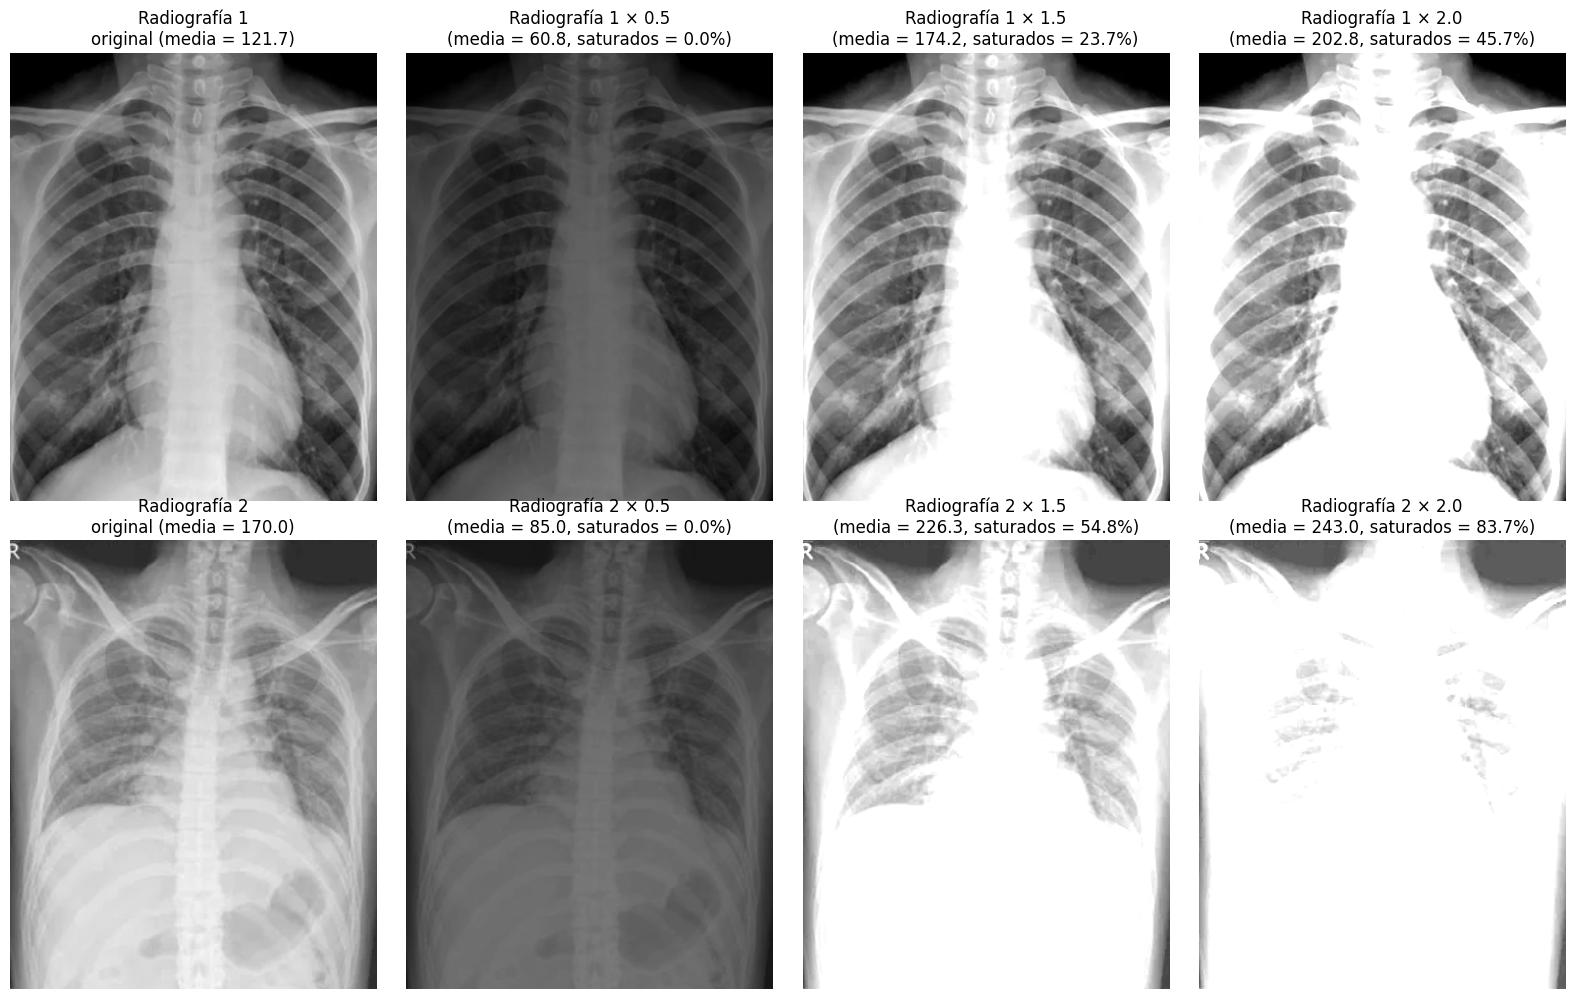

In [ ]:
# Parte I: Ejercicio 3-Multiplicación por un factor

factores = [0.5, 1.5, 2.0]
imagenes = [(img1, 'Radiografía 1'), (img2, 'Radiografía 2')]

fig, axs = plt.subplots(2, 4, figsize=(16, 10))
for fila, (img, nombre) in enumerate(imagenes):
    axs[fila, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
    axs[fila, 0].set_title(f'{nombre}\noriginal (media = {img.mean():.1f})')
    axs[fila, 0].axis('off')
    for col, f in enumerate(factores, start=1):
        # convertScaleAbs: alpha * pixel
        res = cv2.convertScaleAbs(img, alpha=f, beta=0)
        axs[fila, col].imshow(res, cmap='gray', vmin=0, vmax=255)
        axs[fila, col].set_title(f'{nombre} × {f}\n(media = {res.mean():.1f}, saturados = {np.mean(res == 255) * 100:.1f}%)')
        axs[fila, col].axis('off')
plt.tight_layout()
plt.show()

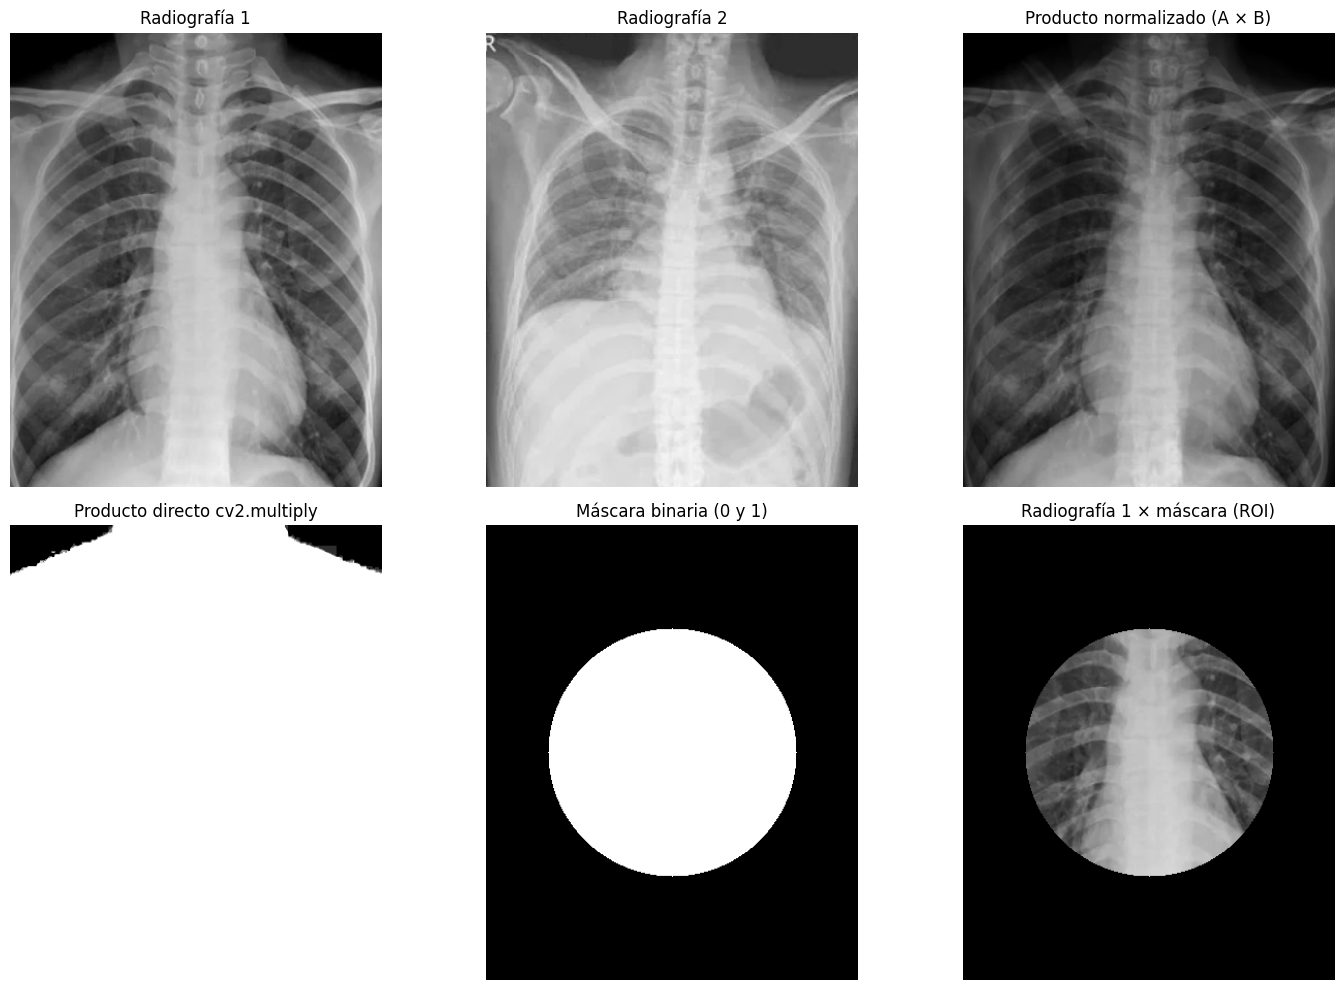

Media del producto normalizado: 86.0
Píxeles saturados en 255 con multiplicación directa: 96.5%


In [ ]:
# Parte I: Ejercicio 4-Multiplicación elemento por elemento

# Multiplicación elemento por elemento
a = img1.astype(np.float32) / 255.0
b = img2.astype(np.float32) / 255.0
producto = (a * b * 255).astype(np.uint8)

# Multiplicación directa
producto_directo = cv2.multiply(img1, img2)

# Multiplicación de una imagen por una máscara binaria
mascara = np.zeros(img1.shape, dtype=np.float32)
cv2.circle(mascara, (w2 // 2, h2 // 2), min(h2, w2) // 3, 1.0, -1)
roi = (img1.astype(np.float32) * mascara).astype(np.uint8)

paneles = [
    (img1, 'Radiografía 1', 'gray'),
    (img2, 'Radiografía 2', 'gray'),
    (producto, 'Producto normalizado (A × B)', 'gray'),
    (producto_directo, 'Producto directo cv2.multiply', 'gray'),
    (mascara, 'Máscara binaria (0 y 1)', 'gray'),
    (roi, 'Radiografía 1 × máscara (ROI)', 'gray'),
]

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for ax, (im, titulo, cm) in zip(axs.ravel(), paneles):
    ax.imshow(im, cmap=cm, vmin=0, vmax=(1 if im.dtype == np.float32 else 255))
    ax.set_title(titulo)
    ax.axis('off')
plt.tight_layout()
plt.show()

print(f"Media del producto normalizado: {producto.mean():.1f}")
print(f"Píxeles saturados en 255 con multiplicación directa: {np.mean(producto_directo == 255) * 100:.1f}%")

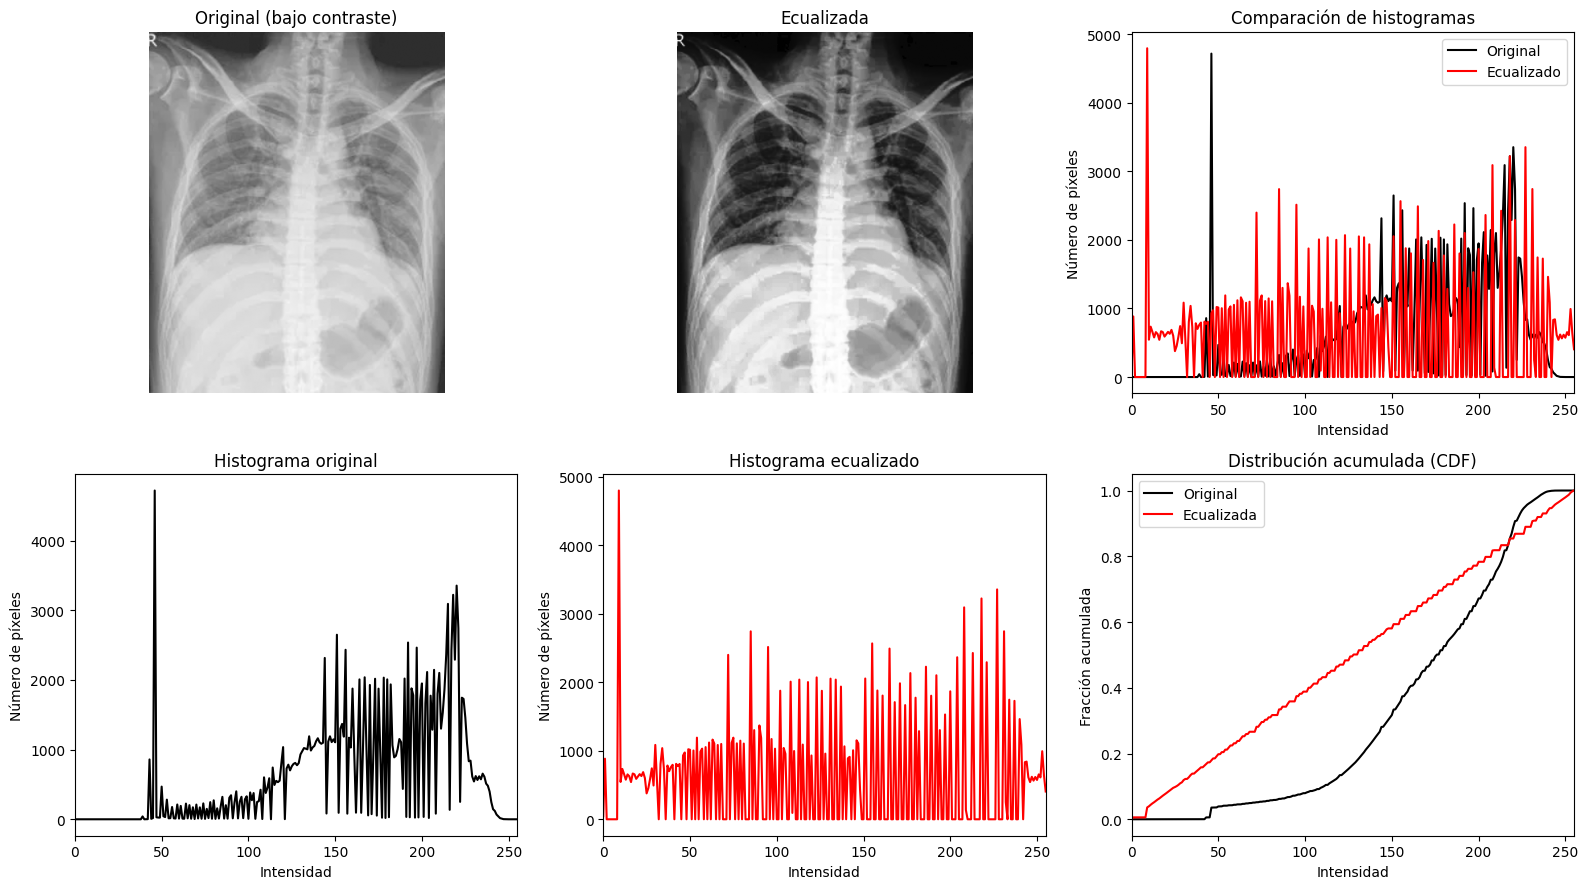

Original  -> min: 34, max: 249, media: 170.0, desv. estándar: 46.8
Ecualizada -> min: 0, max: 255, media: 128.8, desv. estándar: 73.8


In [ ]:
# Parte II: Ejercicio 1-Ecualización de histograma

img_bc = img2

hist_orig = cv2.calcHist([img_bc], [0], None, [256], [0, 256]).ravel()
ecualizada = cv2.equalizeHist(img_bc)
hist_eq = cv2.calcHist([ecualizada], [0], None, [256], [0, 256]).ravel()

# Funciones de distribución acumulada normalizadas
cdf_orig = hist_orig.cumsum() / hist_orig.sum()
cdf_eq = hist_eq.cumsum() / hist_eq.sum()

fig, axs = plt.subplots(2, 3, figsize=(16, 9))

axs[0, 0].imshow(img_bc, cmap='gray', vmin=0, vmax=255)
axs[0, 0].set_title('Original (bajo contraste)')
axs[0, 0].axis('off')

axs[0, 1].imshow(ecualizada, cmap='gray', vmin=0, vmax=255)
axs[0, 1].set_title('Ecualizada')
axs[0, 1].axis('off')

axs[0, 2].plot(hist_orig, color='black', label='Original')
axs[0, 2].plot(hist_eq, color='red', label='Ecualizado')
axs[0, 2].set_title('Comparación de histogramas')
axs[0, 2].set_xlabel('Intensidad')
axs[0, 2].set_ylabel('Número de píxeles')
axs[0, 2].set_xlim([0, 255])
axs[0, 2].legend()

axs[1, 0].plot(hist_orig, color='black')
axs[1, 0].set_title('Histograma original')
axs[1, 0].set_xlabel('Intensidad')
axs[1, 0].set_ylabel('Número de píxeles')
axs[1, 0].set_xlim([0, 255])

axs[1, 1].plot(hist_eq, color='red')
axs[1, 1].set_title('Histograma ecualizado')
axs[1, 1].set_xlabel('Intensidad')
axs[1, 1].set_ylabel('Número de píxeles')
axs[1, 1].set_xlim([0, 255])

axs[1, 2].plot(cdf_orig, color='black', label='Original')
axs[1, 2].plot(cdf_eq, color='red', label='Ecualizada')
axs[1, 2].set_title('Distribución acumulada (CDF)')
axs[1, 2].set_xlabel('Intensidad')
axs[1, 2].set_ylabel('Fracción acumulada')
axs[1, 2].set_xlim([0, 255])
axs[1, 2].legend()

plt.tight_layout()
plt.show()

print(f"Original  -> min: {img_bc.min()}, max: {img_bc.max()}, media: {img_bc.mean():.1f}, desv. estándar: {img_bc.std():.1f}")
print(f"Ecualizada -> min: {ecualizada.min()}, max: {ecualizada.max()}, media: {ecualizada.mean():.1f}, desv. estándar: {ecualizada.std():.1f}")

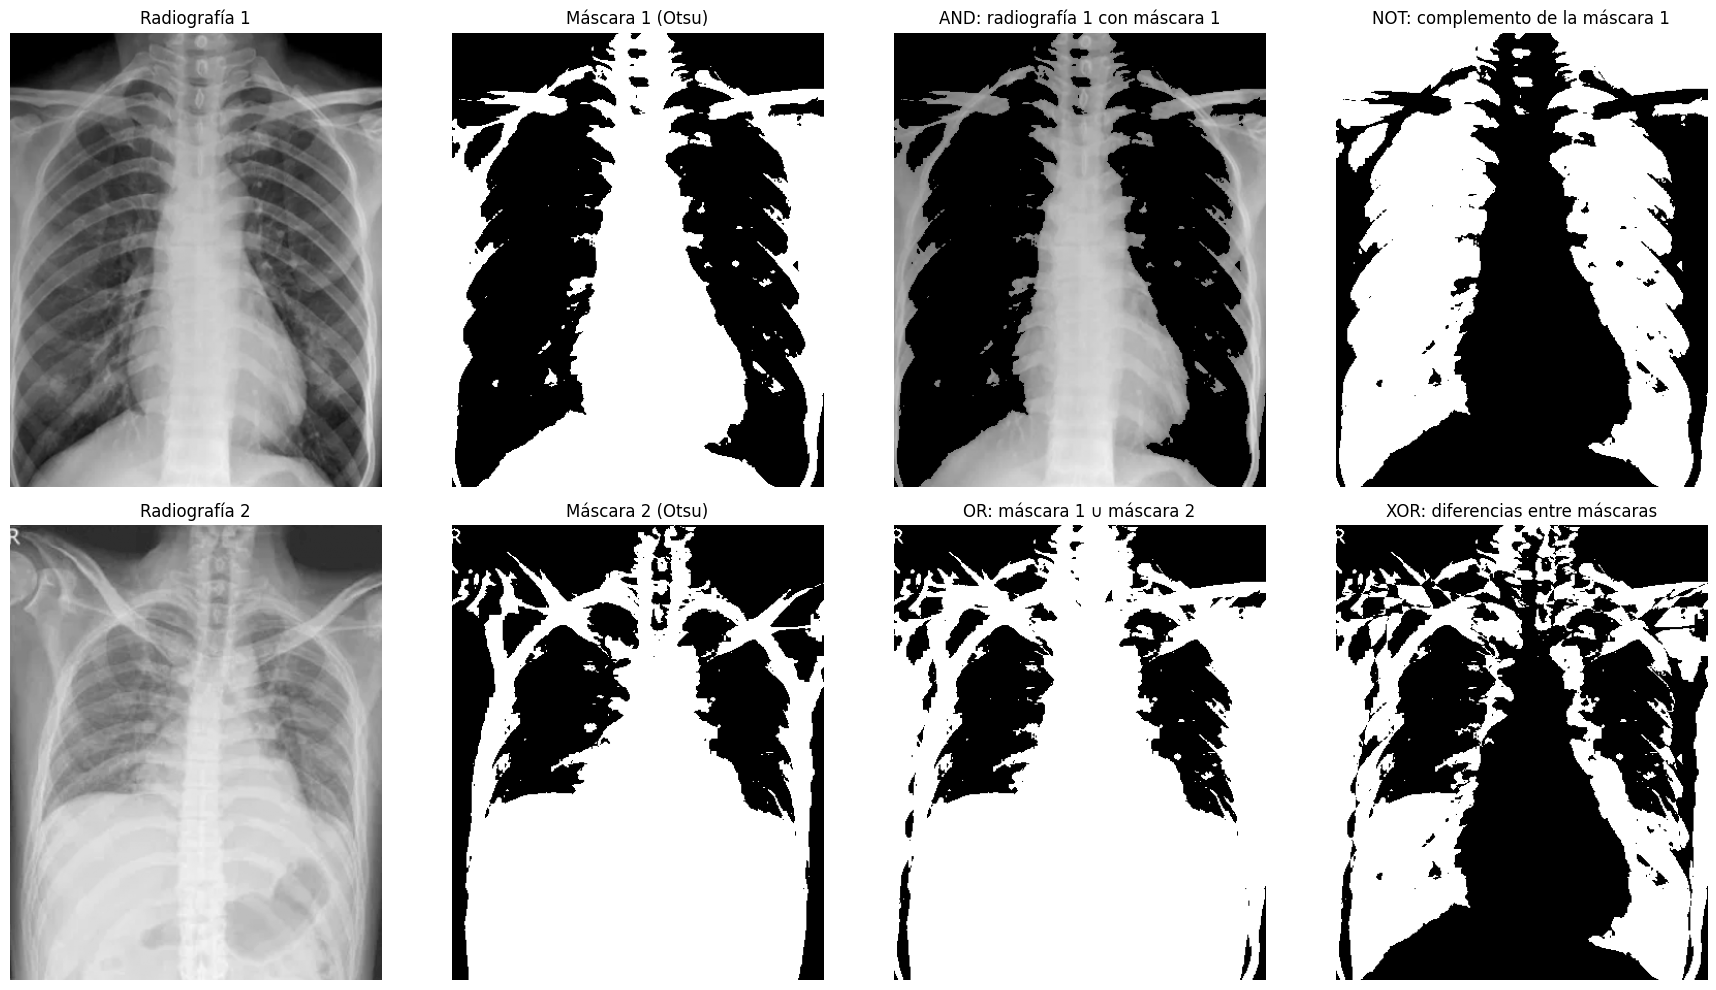

In [ ]:
# Operaciones lógicas con máscaras)
# Otsu
_, mask1 = cv2.threshold(img1, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, mask2 = cv2.threshold(img2, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

and_img = cv2.bitwise_and(img1, img1, mask=mask1)   # aísla la región segmentada
not_mask = cv2.bitwise_not(mask1)                   # complemento de la máscara
or_masks = cv2.bitwise_or(mask1, mask2)             # unión de las dos regiones
xor_masks = cv2.bitwise_xor(mask1, mask2)           # zonas donde las máscaras difieren

paneles = [
    (img1, 'Radiografía 1'),
    (mask1, 'Máscara 1 (Otsu)'),
    (and_img, 'AND: radiografía 1 con máscara 1'),
    (not_mask, 'NOT: complemento de la máscara 1'),
    (img2, 'Radiografía 2'),
    (mask2, 'Máscara 2 (Otsu)'),
    (or_masks, 'OR: máscara 1 ∪ máscara 2'),
    (xor_masks, 'XOR: diferencias entre máscaras'),
]

fig, axs = plt.subplots(2, 4, figsize=(18, 10))
for ax, (im, titulo) in zip(axs.ravel(), paneles):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis('off')
plt.tight_layout()
plt.show()